In [1]:
%load_ext autoreload
%autoreload 2

https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd

In [2]:
import os

import sparrow as sp

the value of the environment variable BASIC_DCT_BACKEND is not in ["JAX","SCIPY"]


In [9]:
from sparrow.datasets.registry import get_registry

custom_cache_dir = r"D:\Data\Visium_HD\sparrow_example"
registry=get_registry(custom_cache_dir)

path_image = registry.fetch( "transcriptomics/visium_hd/mouse/Visium_HD_Mouse_Small_Intestine_tissue_image.btf" )
path_barcode_positions = registry.fetch( "transcriptomics/visium_hd/mouse/binned_outputs/square_002um/spatial/tissue_positions.parquet" ) # barcode positions
path_raw_h5_file = registry.fetch( "transcriptomics/visium_hd/mouse/binned_outputs/square_002um/filtered_feature_bc_matrix.h5" )

create empty spatialdata object

In [10]:
import dask.array as da
from spatialdata import SpatialData
from tifffile import imread

output_path = r'D:\Data\Visium_HD\sparrow_example'

img = imread( path_image )

sdata=SpatialData()
sdata.write( os.path.join( output_path, "sdata_custom_binning_visium_hd.zarr" ) )

INFO     The Zarr backing store has been changed from None the new file path:                                      
         D:\Data\Visium_HD\sparrow_example\sdata_custom_binning_visium_hd.zarr                                     


In [13]:
da.asarray(img).transpose( 2,0,1 )

dask.array<transpose, shape=(3, 21943, 23618), dtype=uint8, chunksize=(3, 6688, 6688), chunktype=numpy.ndarray>

add image

In [11]:
sdata=sp.im.add_image_layer(
    sdata,
    arr = da.asarray(img).transpose( 2,0,1 ),
    output_layer = "raw_image",
    overwrite=True,
        )

2024-09-18 15:00:01,435 - sparrow.image._manager - WARNING - No dims parameter specified. Assuming order of dimension of provided array is ((c), (z), y, x)
2024-09-18 15:00:01,449 - sparrow.image._manager - INFO - Writing results to layer 'raw_image'


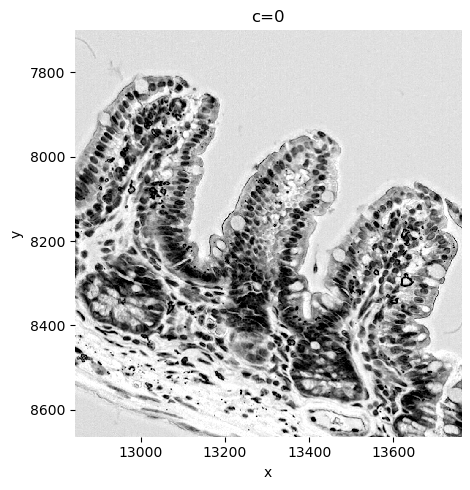

In [14]:
sp.pl.plot_image( sdata, img_layer="raw_image", crd =[ 12844, 13760, 7700, 8664 ], figsize=(5,5), channel=0 )

Add grid with same dimensions as image. We assume that barcode locations are registered to the image

(latter two cells can probably be speed up using dask geopandas as format the shapes layers are saved in harpy)

In [15]:
size = 32
sdata = sp.im.add_grid_labels_layer( sdata, shape = sdata[ "raw_image" ].shape[1:], size=size, output_shapes_layer="square_shapes", output_labels_layer="square_labels", grid_type="square" )



AttributeError: module 'sparrow.image' has no attribute 'add_grid_labels_layer'

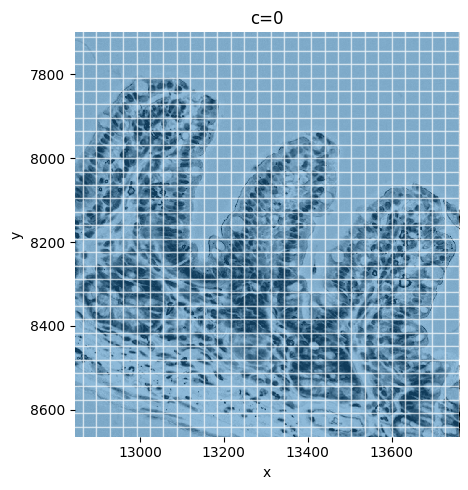

In [8]:
sp.pl.plot_shapes( sdata, img_layer="raw_image", crd =[ 12844, 13760, 7700, 8664 ], channel=0, shapes_layer="square_shapes", figsize = (5,5) )

In [9]:
import dask.dataframe as dd

# Load the Spatial Coordinates -> contains location of each 2*2 barcode square where each row is a barcode.
df_tissue_positions=dd.read_parquet( path_barcode_positions )

In [10]:
df_tissue_positions.head()

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,24543.676218,-700.350277
1,s_002um_00000_00001-1,0,0,1,24543.627437,-693.046444
2,s_002um_00000_00002-1,0,0,2,24543.578656,-685.742611
3,s_002um_00000_00003-1,0,0,3,24543.529875,-678.438777
4,s_002um_00000_00004-1,0,0,4,24543.481093,-671.134944


In [11]:
coordinates = {"x": "pxl_col_in_fullres", "y": "pxl_row_in_fullres"}

sdata=sp.pt.add_points_layer( sdata, ddf=df_tissue_positions, coordinates=coordinates, overwrite=True, output_layer = "barcodes_location" )

In [12]:
sdata[ "barcodes_location" ].head()

,x,y,barcode,in_tissue,array_col,array_row
0,-700.350277,24543.676218,s_002um_00000_00000-1,0,0,0
1,-693.046444,24543.627437,s_002um_00000_00001-1,0,1,0
2,-685.742611,24543.578656,s_002um_00000_00002-1,0,2,0
3,-678.438777,24543.529875,s_002um_00000_00003-1,0,3,0
4,-671.134944,24543.481093,s_002um_00000_00004-1,0,4,0


2024-09-18 10:01:57,681 - sparrow.plot._sanity - INFO - size before sampling is 182
2024-09-18 10:01:57,959 - sparrow.plot._sanity - INFO - Plotting 182 transcripts.
2024-09-18 10:01:57,961 - sparrow.plot._sanity - INFO - Selecting boundaries
2024-09-18 10:02:03,801 - sparrow.plot._sanity - INFO - Plotting boundaries
2024-09-18 10:02:03,827 - sparrow.plot._sanity - INFO - End plotting boundaries


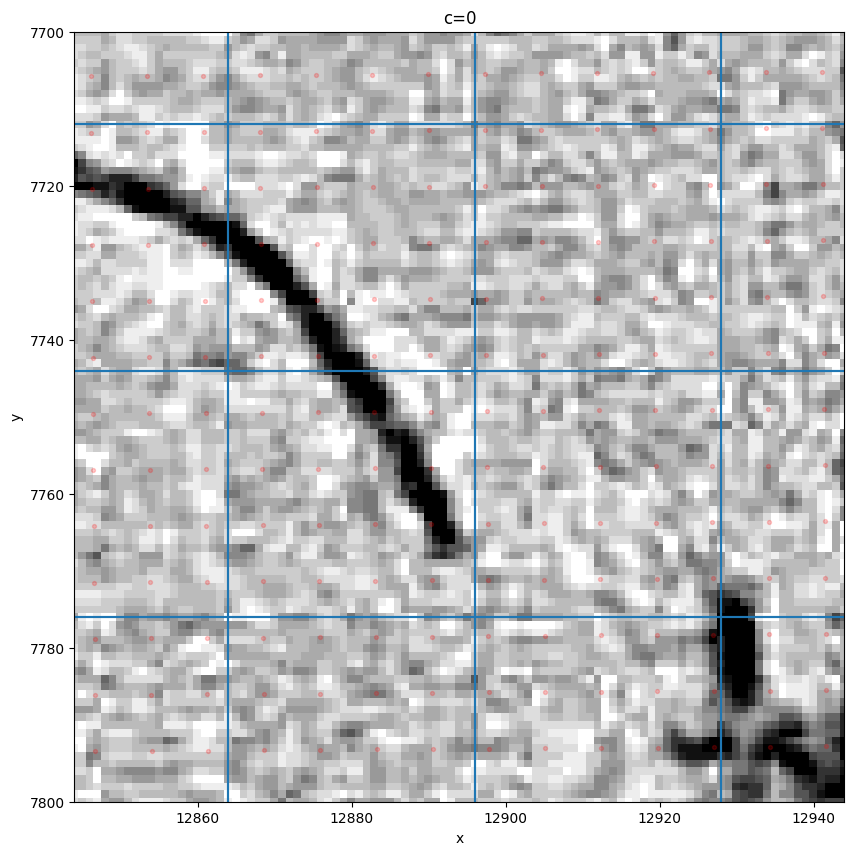

In [13]:
sp.pl.sanity_plot_transcripts_matrix( sdata, img_layer="raw_image", channel=0, points_layer="barcodes_location",  crd =[ 12844, 12844+100, 7700, 7700+100 ], name_gene_column="barcode", shapes_layer="square_shapes" )

In [14]:
# load visium hd data

import scanpy as sc

adata = sc.read_10x_h5( path_raw_h5_file  )

assert adata.obs.index.is_unique  # sanity check on visium data. We do not want to count something twice

adata.var_names_make_unique()

/Users/arnedf/miniconda3/envs/harpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/arnedf/miniconda3/envs/harpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [15]:
sdata[ "barcodes_location" ].head()

,x,y,barcode,in_tissue,array_col,array_row
0,-700.350277,24543.676218,s_002um_00000_00000-1,0,0,0
1,-693.046444,24543.627437,s_002um_00000_00001-1,0,1,0
2,-685.742611,24543.578656,s_002um_00000_00002-1,0,2,0
3,-678.438777,24543.529875,s_002um_00000_00003-1,0,3,0
4,-671.134944,24543.481093,s_002um_00000_00004-1,0,4,0


In [16]:
adata.obs.head()  # these barcodes will be matched with 'barcode' column in points layer 'barcodes_location', after 'barcode' from points layer is assigned a cell/region in 'square_labels'

""
s_002um_00700_02130-1
s_002um_02043_00141-1
s_002um_02278_00850-1
s_002um_01729_00511-1
s_002um_02148_02515-1


In [17]:
# should take around 1min (on mac m2)
sdata = sp.tb.bin_counts(
    sdata,
    adata=adata,
    points_layer="barcodes_location",
    labels_layer="square_labels",
    output_layer="table_custom_bin_32",
    name_barcode_id="barcode",  # name of barcode in the points layer, will be matches with adata.obs.index
    overwrite=True,
    append=False,
)

2024-09-18 10:02:15,771 - sparrow.table._allocation - INFO - Calculating cell counts.
2024-09-18 10:02:44,994 - sparrow.table._allocation - INFO - 
 Number of spots per bin  Frequency
                       1          1
                       4         43
                       5         26
                       8         42
                       9          3
                      10         27
                      12         74
                      13          2
                      14          1
                      15         47
                      16     181025
                      17       8001
                      18       8137
                      19       8188
                      20     216441
                      21       5060
                      22       4972
                      23       4884
                      24       4763
                      25      63506
/Users/arnedf/miniconda3/envs/harpy/lib/python3.10/site-packages/anndata/_core/aligned_df.py:67:

In [18]:
sdata[ "table_custom_bin_32" ]

AnnData object with n_obs × n_vars = 294038 × 19059
    obs: 'cell_ID', 'fov_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

2024-09-18 10:04:25,050 - sparrow.plot._plot - WARNING - There are '285' cells in provided shapes_layer 'square_shapes' not found in 'sdata.tables[table_custom_bin_32]' (linked through 'cell_ID'), these cells will not be plotted.


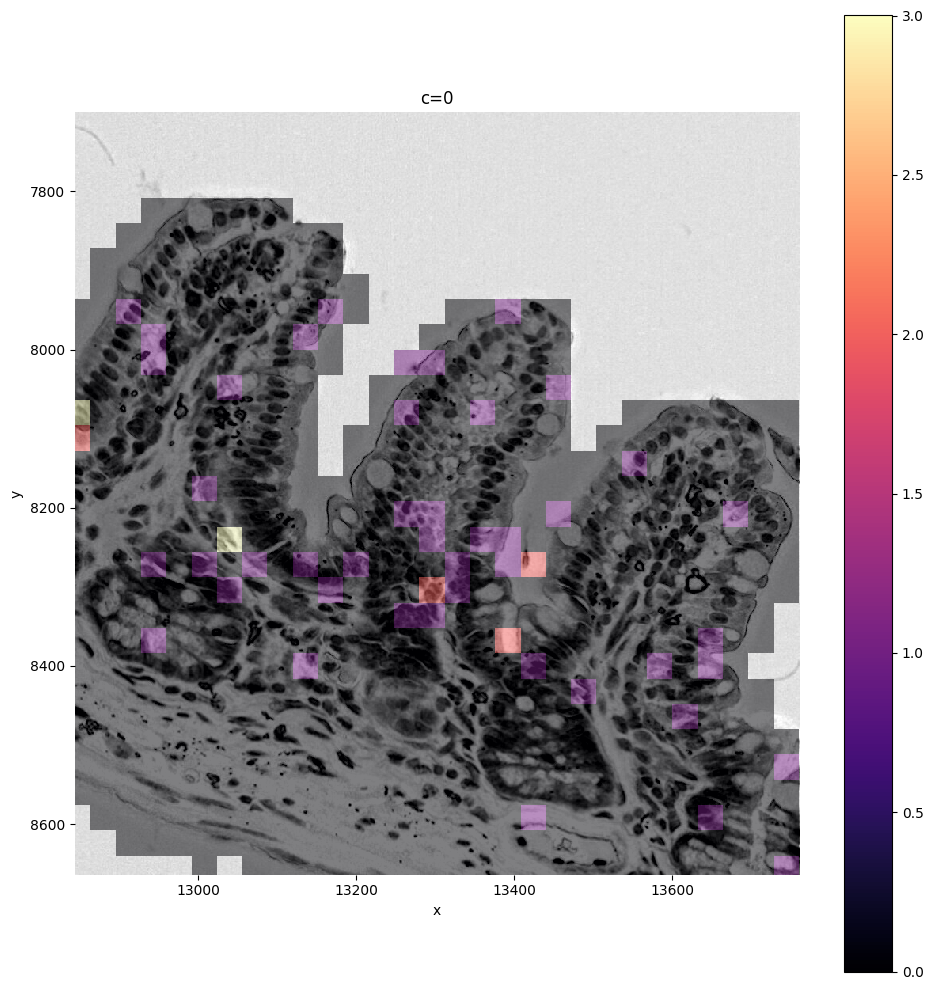

In [22]:
sp.pl.plot_shapes(
    sdata,
    img_layer = "raw_image",
    shapes_layer="square_shapes",
    crd = [ 12844, 13760, 7700, 8664 ],
    channel=0,
    table_layer = "table_custom_bin_32",
    column="Lypla1",
    linewidth=0,
      )

2024-09-18 10:04:34,104 - sparrow.plot._plot - WARNING - There are '9421' cells in provided shapes_layer 'square_shapes' not found in 'sdata.tables[table_custom_bin_32]' (linked through 'cell_ID'), these cells will not be plotted.


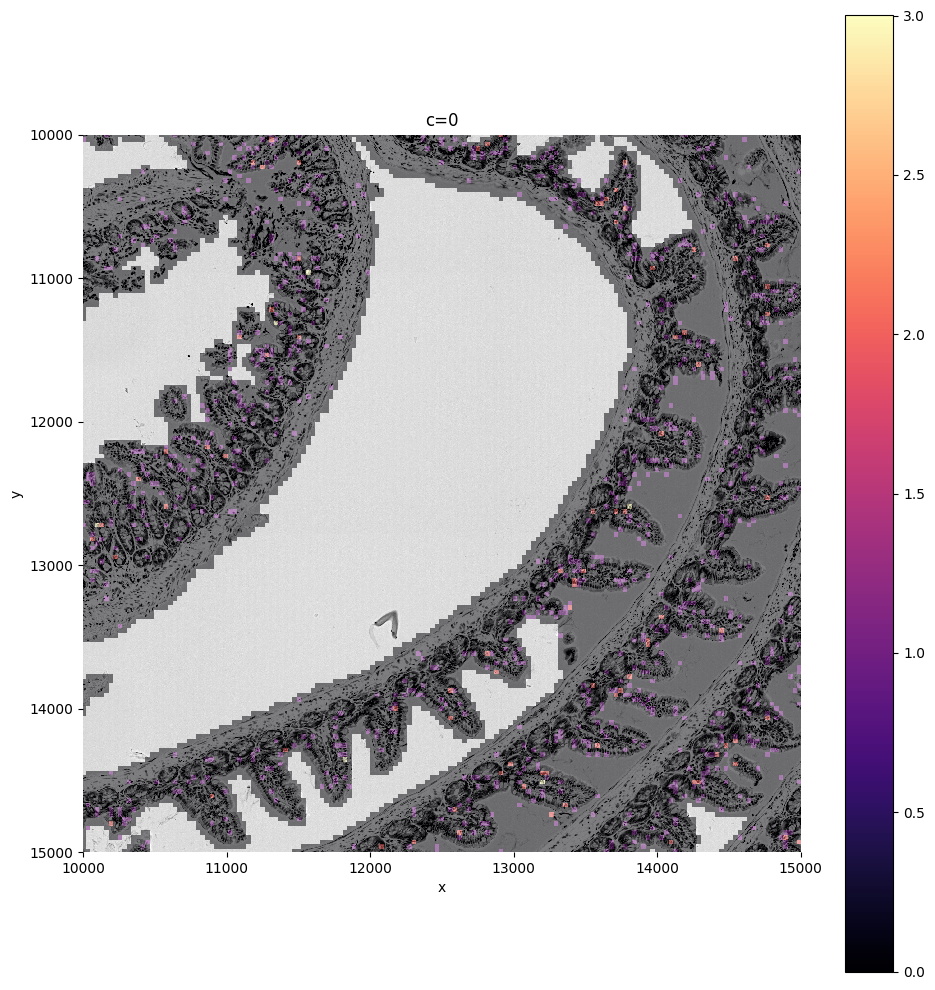

In [23]:
sp.pl.plot_shapes(
    sdata,
    img_layer = "raw_image",
    shapes_layer="square_shapes",
    crd = [10000, 15000, 10000, 15000 ],
    channel=0,
    table_layer = "table_custom_bin_32",
    linewidth=0,
    column="Lypla1",
    )

In [24]:
# you can then proceed doing normalization 
#adata_norm=sc.pp.normalize_total( sdata.tables[ "table_custom_bin_32" ] )

In [26]:
#np.where(sdata.tables[ "table_custom_bin_32" ].X[0].toarray() !=0 )

(array([0, 0, 0]), array([ 7337, 13546, 13963]))

In [28]:
#sdata.tables[ "table_custom_bin_32" ].X[0].toarray()[ :, 7337 ]

array([127.])

In [183]:
#sp.pl.sanity_plot_transcripts_matrix( sdata, img_layer="raw_image", points_layer = "barcodes_location" , shapes_layer = "segmentation_boundaries",  crd = [ 12844, 13760, 7700, 8664 ], plot_cell_number=False )